# 1D heat equation: explicit finite differences

Solve $u_t = u_{xx}$ on $[0, 1]$ with Dirichlet BCs $u(0, t) = u(1, t) = 0$
and initial condition $u(x, 0) = \sin(\pi x) + 0.5 \sin(3 \pi x)$.
Explicit Euler in time, 3-point stencil in space.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)

## 1. Grid and stability

For the explicit scheme $u_i^{n+1} = u_i^n + \lambda (u_{i+1}^n - 2 u_i^n + u_{i-1}^n)$
with $\lambda = k / h^2$, von Neumann analysis gives the CFL condition

$$k \leq \frac{h^2}{2}.$$

Violating it produces oscillations that blow up.

In [2]:
L = 1.0
nx = 51
h = L / (nx - 1)
x = np.linspace(0, L, nx)

k_max = 0.5 * h**2
k = 0.4 * h**2            # safely under CFL
lam = k / h**2
T_end = 0.1
nt = int(np.ceil(T_end / k))
k = T_end / nt            # adjust so nt*k lands exactly on T_end
lam = k / h**2

print(f"h = {h:.4f},  k = {k:.6f},  lambda = k/h^2 = {lam:.4f}  (needs <= 0.5)")
print(f"nt = {nt}  steps to reach T = {T_end}")

h = 0.0200,  k = 0.000160,  lambda = k/h^2 = 0.4000  (needs <= 0.5)
nt = 625  steps to reach T = 0.1


## 2. Initial condition and time stepping

In [3]:
u = np.sin(np.pi * x) + 0.5 * np.sin(3 * np.pi * x)
u[0] = u[-1] = 0.0                # enforce BC

snap_times = [0.0, 0.005, 0.02, 0.05, 0.1]
snaps = {0.0: u.copy()}

t = 0.0
for n in range(nt):
    u_new = u.copy()
    u_new[1:-1] = u[1:-1] + lam * (u[2:] - 2 * u[1:-1] + u[:-2])
    u_new[0] = u_new[-1] = 0.0
    u = u_new
    t += k
    # record the nearest requested snapshot once
    for s in snap_times:
        if s > 0 and s not in snaps and t >= s - 1e-12:
            snaps[s] = u.copy()
            break

## 3. Plot the solution at several times

High-frequency modes damp fastest: the $\sin(3\pi x)$ component decays as
$e^{-9 \pi^2 t}$, so by $t = 0.05$ almost only the fundamental is left.

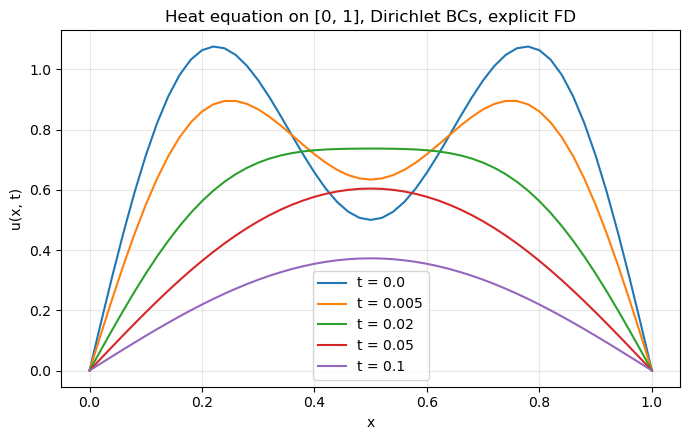

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for s in sorted(snaps):
    ax.plot(x, snaps[s], label=f"t = {s}")
ax.set_xlabel("x")
ax.set_ylabel("u(x, t)")
ax.set_title("Heat equation on [0, 1], Dirichlet BCs, explicit FD")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Verify against the analytical solution

The sine series solution is

$$u(x, t) = e^{-\pi^2 t} \sin(\pi x) + 0.5\, e^{-9 \pi^2 t} \sin(3 \pi x).$$

Max |numerical - exact| at T = 0.1: 1.670e-04


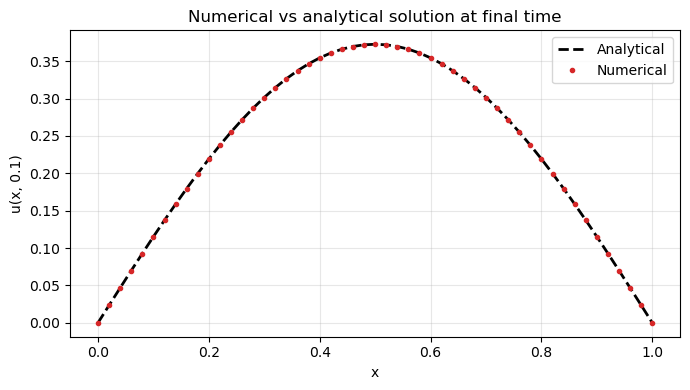

In [5]:
u_exact = np.exp(-np.pi**2 * T_end) * np.sin(np.pi * x) + \
          0.5 * np.exp(-9 * np.pi**2 * T_end) * np.sin(3 * np.pi * x)

err = np.max(np.abs(u - u_exact))
print(f"Max |numerical - exact| at T = {T_end}: {err:.3e}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(x, u_exact, "k--", lw=2, label="Analytical")
ax.plot(x, u, "o", markersize=3, color="tab:red", label="Numerical")
ax.set_xlabel("x")
ax.set_ylabel(f"u(x, {T_end})")
ax.set_title("Numerical vs analytical solution at final time")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Exercises

1. Rerun the solver with $k = 0.6 \, h^2$ (above CFL) and plot the solution
   at $t = 0.02$. Describe what you see.
2. Replace Dirichlet with homogeneous Neumann BCs ($u_x = 0$ at both ends)
   and verify that total "heat" $\int u \, dx$ is conserved.
3. Switch to the implicit (backward Euler) scheme. It solves a tridiagonal
   system per step but is unconditionally stable. Use `scipy.linalg.solve_banded`.